In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"C:\India_Vs_West_Indies_T20i_Challenge")

CLEAN_FILE = (
    PROJECT_DIR
    / "Data"
    / "Clean"
    / "t20i_ball_by_ball_clean.csv"
)

df = pd.read_csv(CLEAN_FILE)

print("Dataset shape:", df.shape)
print("Matches:", df["MatchDay"].nunique())
print("Innings:", df[["MatchDay", "Innings"]].drop_duplicates().shape[0])

display(df.head())

Dataset shape: (959, 24)
Matches: 4
Innings: 8


,Venue,MatchDay,Innings,Batting Team,Bowling Team,Striker,Non-Striker,Bowler,Ball Number,Actual Ball Number,...,Wide,No Ball,Leg Bye,Bye,Wicket,4's,6's,Run_QC_Flag,Extras_QC_Flag,Ball_Number_Label
0,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.1,0.1,...,0,0,0,0,0,0,0,False,False,0.1
1,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.2,0.2,...,0,0,0,0,0,0,0,False,False,0.2
2,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.3,0.3,...,0,0,0,0,0,0,0,False,False,0.3
3,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.4,0.4,...,0,0,0,0,0,1,0,False,False,0.4
4,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.5,0.5,...,0,0,0,0,0,0,0,False,False,0.5


In [3]:
# Convert extras columns to numeric values
extra_cols = ["Wide", "No Ball", "Leg Bye", "Bye"]

for col in extra_cols:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    ).fillna(0)

# Recalculate legal deliveries
df["Legal_Ball"] = (
    (df["Wide"] == 0) &
    (df["No Ball"] == 0)
).astype(int)

# Runs charged to the bowler
df["Bowler_Runs_Conceded"] = (
    df["Runs Off The Bat"] +
    df["Wide"] +
    df["No Ball"]
)

# Extract the over number from the ball-number notation
ball_text = (
    df["Ball Number"]
    .astype(str)
    .str.strip()
)

df["Over_Number"] = pd.to_numeric(
    ball_text.str.split(".").str[0],
    errors="coerce"
).astype("Int64")

# Assign bowling phases
df["Phase"] = np.select(
    [
        df["Over_Number"].between(1, 6),
        df["Over_Number"].between(7, 15),
        df["Over_Number"].between(16, 20)
    ],
    [
        "Powerplay",
        "Middle Overs",
        "Death Overs"
    ],
    default="Unknown"
)

print("Phase distribution:")
display(df["Phase"].value_counts().to_frame("Deliveries"))

print("\nSample records:")
display(
    df[
        [
            "MatchDay",
            "Innings",
            "Ball Number",
            "Over_Number",
            "Phase",
            "Legal_Ball",
            "Bowler_Runs_Conceded"
        ]
    ].head(10)
)

Phase distribution:


,Deliveries
Phase,
Middle Overs,447
Powerplay,304
Death Overs,160
Unknown,48



Sample records:


,MatchDay,Innings,Ball Number,Over_Number,Phase,Legal_Ball,Bowler_Runs_Conceded
0,1,1,0.1,0,Unknown,1,0
1,1,1,0.2,0,Unknown,1,0
2,1,1,0.3,0,Unknown,1,0
3,1,1,0.4,0,Unknown,1,4
4,1,1,0.5,0,Unknown,1,0
5,1,1,0.6,0,Unknown,1,1
6,1,1,1.1,1,Powerplay,1,4
7,1,1,1.2,1,Powerplay,1,4
8,1,1,1.3,1,Powerplay,1,0
9,1,1,1.4,1,Powerplay,1,0


In [4]:
# Check for missing over numbers
print("Missing over numbers:", df["Over_Number"].isna().sum())

# Check for unexpected over numbers
invalid_overs = df[
    ~df["Over_Number"].between(1, 20)
]

print("Deliveries outside overs 1–20:", len(invalid_overs))

# Check phase assignments
print("\nPhase distribution:")
display(
    df.groupby("Phase", dropna=False)
      .agg(
          Deliveries=("Ball Number", "size"),
          Legal_Balls=("Legal_Ball", "sum"),
          Runs_Off_Bat=("Runs Off The Bat", "sum"),
          Bowler_Runs=("Bowler_Runs_Conceded", "sum")
      )
      .reset_index()
)

# Inspect any records requiring attention
if len(invalid_overs) > 0:
    display(
        invalid_overs[
            ["MatchDay", "Innings", "Ball Number", "Over_Number", "Phase"]
        ].head(20)
    )

Missing over numbers: 0
Deliveries outside overs 1–20: 48

Phase distribution:


,Phase,Deliveries,Legal_Balls,Runs_Off_Bat,Bowler_Runs
0,Death Overs,160,151,326,339
1,Middle Overs,447,424,738,761
2,Powerplay,304,288,544,564
3,Unknown,48,48,54,54


,MatchDay,Innings,Ball Number,Over_Number,Phase
0,1,1,0.1,0,Unknown
1,1,1,0.2,0,Unknown
2,1,1,0.3,0,Unknown
3,1,1,0.4,0,Unknown
4,1,1,0.5,0,Unknown
5,1,1,0.6,0,Unknown
116,1,2,0.1,0,Unknown
117,1,2,0.2,0,Unknown
118,1,2,0.3,0,Unknown
119,1,2,0.4,0,Unknown


In [5]:
# Inspect the earliest and latest ball numbers
print("First 30 unique ball numbers:")
print(sorted(df["Ball Number"].astype(str).unique(),
             key=lambda x: float(x))[:30])

print("\nOver-number counts:")
display(
    df["Over_Number"]
    .value_counts()
    .sort_index()
    .to_frame("Deliveries")
    .head(25)
)

print("\nSample of first-over deliveries:")
display(
    df.loc[
        df["Ball Number"].astype(str).str.startswith("0."),
        ["MatchDay", "Innings", "Ball Number", "Over_Number", "Phase"]
    ].head(20)
)

First 30 unique ball numbers:
['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '1.1', '1.2', '1.3', '1.4', '1.5', '1.6', '1.7', '2.1', '2.2', '2.3', '2.4', '2.5', '2.6', '2.7', '2.8', '2.9', '3.1', '3.2', '3.3', '3.4', '3.5', '3.6', '4.1', '4.2']

Over-number counts:


,Deliveries
Over_Number,
0,48
1,49
2,55
3,48
4,51
5,50
6,51
7,49
8,50



Sample of first-over deliveries:


,MatchDay,Innings,Ball Number,Over_Number,Phase
0,1,1,0.1,0,Unknown
1,1,1,0.2,0,Unknown
2,1,1,0.3,0,Unknown
3,1,1,0.4,0,Unknown
4,1,1,0.5,0,Unknown
5,1,1,0.6,0,Unknown
116,1,2,0.1,0,Unknown
117,1,2,0.2,0,Unknown
118,1,2,0.3,0,Unknown
119,1,2,0.4,0,Unknown


In [6]:
# Convert the original ball-number notation to text
ball_text = df["Ball Number"].astype(str).str.strip()

# Extract the over index and convert it to cricket over numbering
df["Over_Index"] = pd.to_numeric(
    ball_text.str.split(".").str[0],
    errors="coerce"
)

df["Over_Number"] = df["Over_Index"] + 1

# Assign bowling phases using actual over numbers
df["Phase"] = np.select(
    [
        df["Over_Number"].between(1, 6),
        df["Over_Number"].between(7, 15),
        df["Over_Number"].between(16, 20)
    ],
    [
        "Powerplay",
        "Middle Overs",
        "Death Overs"
    ],
    default="Unknown"
)

# Validate the corrected phase assignments
print("Missing over numbers:", df["Over_Number"].isna().sum())
print(
    "Deliveries outside overs 1–20:",
    (~df["Over_Number"].between(1, 20)).sum()
)
print("Unknown-phase deliveries:", (df["Phase"] == "Unknown").sum())

display(
    df.groupby("Phase", dropna=False)
      .agg(
          Deliveries=("Ball Number", "size"),
          Legal_Balls=("Legal_Ball", "sum"),
          Runs_Off_Bat=("Runs Off The Bat", "sum"),
          Bowler_Runs=("Bowler_Runs_Conceded", "sum")
      )
      .reset_index()
)

Missing over numbers: 0
Deliveries outside overs 1–20: 0
Unknown-phase deliveries: 0


,Phase,Deliveries,Legal_Balls,Runs_Off_Bat,Bowler_Runs
0,Death Overs,203,193,404,418
1,Middle Overs,455,430,731,756
2,Powerplay,301,288,527,544


In [7]:
# Summarise bowling performance by phase
phase_bowling = (
    df.groupby(
        ["Phase", "Bowler", "Bowling Team"],
        as_index=False
    )
    .agg(
        Deliveries=("Ball Number", "size"),
        Legal_Balls=("Legal_Ball", "sum"),
        Runs_Conceded=("Bowler_Runs_Conceded", "sum"),
        Wicket_Events=("Wicket", "sum")
    )
)

# Convert legal balls to cricket overs notation
phase_bowling["Overs"] = (
    (phase_bowling["Legal_Balls"] // 6).astype(int).astype(str)
    + "."
    + (phase_bowling["Legal_Balls"] % 6).astype(int).astype(str)
)

# Calculate economy using legal balls
phase_bowling["Economy"] = (
    phase_bowling["Runs_Conceded"] * 6
    / phase_bowling["Legal_Balls"].replace(0, np.nan)
).round(2)

# Sort by phase and economy
phase_order = {
    "Powerplay": 1,
    "Middle Overs": 2,
    "Death Overs": 3
}

phase_bowling["Phase_Order"] = phase_bowling["Phase"].map(phase_order)

phase_bowling = (
    phase_bowling.sort_values(
        ["Phase_Order", "Economy"],
        ascending=[True, True]
    )
    .drop(columns="Phase_Order")
    .reset_index(drop=True)
)

display(phase_bowling)

,Phase,Bowler,Bowling Team,Deliveries,Legal_Balls,Runs_Conceded,Wicket_Events,Overs,Economy
0,Powerplay,Axar Patel,India National Cricket team,24,24,32,3,4.0,8.00
1,Powerplay,Mayank Yadav,India National Cricket team,58,54,90,3,9.0,10.00
2,Powerplay,Prince Yadav,India National Cricket team,13,12,20,0,2.0,10.00
3,Powerplay,Arshdeep Singh,India National Cricket team,57,54,100,2,9.0,11.11
4,Powerplay,Akeal Hosein,West Indies Cricket Team,31,30,56,1,5.0,11.20
5,Powerplay,Roston Chase,West Indies Cricket Team,43,42,83,2,7.0,11.86
6,Powerplay,Keemo Paul,West Indies Cricket Team,13,12,24,2,2.0,12.00
7,Powerplay,Romario Shepherd,West Indies Cricket Team,18,18,36,0,3.0,12.00
8,Powerplay,Shamar Joseph,West Indies Cricket Team,25,24,57,1,4.0,14.25
9,Powerplay,Matthew Forde,West Indies Cricket Team,6,6,15,0,1.0,15.00


In [8]:
# Summarise the overall bowling performance in each phase
phase_summary = (
    df.groupby("Phase", as_index=False)
    .agg(
        Deliveries=("Ball Number", "size"),
        Legal_Balls=("Legal_Ball", "sum"),
        Runs_Off_Bat=("Runs Off The Bat", "sum"),
        Bowler_Runs_Conceded=("Bowler_Runs_Conceded", "sum"),
        Wicket_Events=("Wicket", "sum")
    )
)

# Calculate economy rate for each phase
phase_summary["Overs"] = (
    (phase_summary["Legal_Balls"] // 6).astype(int).astype(str)
    + "."
    + (phase_summary["Legal_Balls"] % 6).astype(int).astype(str)
)

phase_summary["Economy"] = (
    phase_summary["Bowler_Runs_Conceded"] * 6
    / phase_summary["Legal_Balls"].replace(0, np.nan)
).round(2)

# Arrange phases in cricket order
phase_order = {
    "Powerplay": 1,
    "Middle Overs": 2,
    "Death Overs": 3
}

phase_summary["Phase_Order"] = phase_summary["Phase"].map(phase_order)

phase_summary = (
    phase_summary.sort_values("Phase_Order")
    .drop(columns="Phase_Order")
    .reset_index(drop=True)
)

display(phase_summary)

,Phase,Deliveries,Legal_Balls,Runs_Off_Bat,Bowler_Runs_Conceded,Wicket_Events,Overs,Economy
0,Powerplay,301,288,527,544,14,48.0,11.33
1,Middle Overs,455,430,731,756,21,71.4,10.55
2,Death Overs,203,193,404,418,15,32.1,12.99


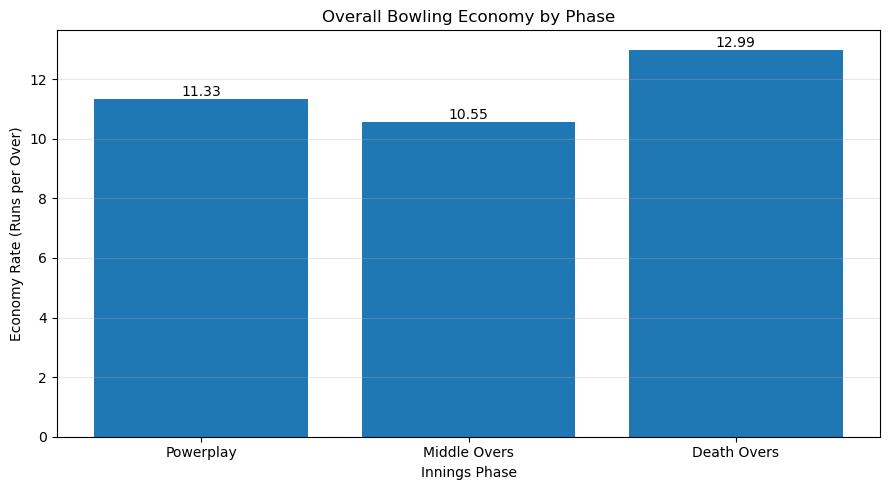

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    phase_summary["Phase"],
    phase_summary["Economy"]
)

# Display economy values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Innings Phase")
plt.ylabel("Economy Rate (Runs per Over)")
plt.title("Overall Bowling Economy by Phase")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Summarise bowling performance by team and phase
team_phase_summary = (
    df.groupby(
        ["Bowling Team", "Phase"],
        as_index=False
    )
    .agg(
        Deliveries=("Ball Number", "size"),
        Legal_Balls=("Legal_Ball", "sum"),
        Runs_Conceded=("Bowler_Runs_Conceded", "sum"),
        Wicket_Events=("Wicket", "sum")
    )
)

# Calculate economy rate
team_phase_summary["Economy"] = (
    team_phase_summary["Runs_Conceded"] * 6
    / team_phase_summary["Legal_Balls"].replace(0, np.nan)
).round(2)

# Put phases in cricket order
phase_order = {
    "Powerplay": 1,
    "Middle Overs": 2,
    "Death Overs": 3
}

team_phase_summary["Phase_Order"] = (
    team_phase_summary["Phase"].map(phase_order)
)

team_phase_summary = (
    team_phase_summary.sort_values(
        ["Phase_Order", "Bowling Team"]
    )
    .drop(columns="Phase_Order")
    .reset_index(drop=True)
)

display(team_phase_summary)

,Bowling Team,Phase,Deliveries,Legal_Balls,Runs_Conceded,Wicket_Events,Economy
0,India National Cricket team,Powerplay,152,144,242,8,10.08
1,West Indies Cricket Team,Powerplay,149,144,302,6,12.58
2,India National Cricket team,Middle Overs,226,216,385,10,10.69
3,West Indies Cricket Team,Middle Overs,229,214,371,11,10.40
4,India National Cricket team,Death Overs,110,106,238,6,13.47
5,West Indies Cricket Team,Death Overs,93,87,180,9,12.41


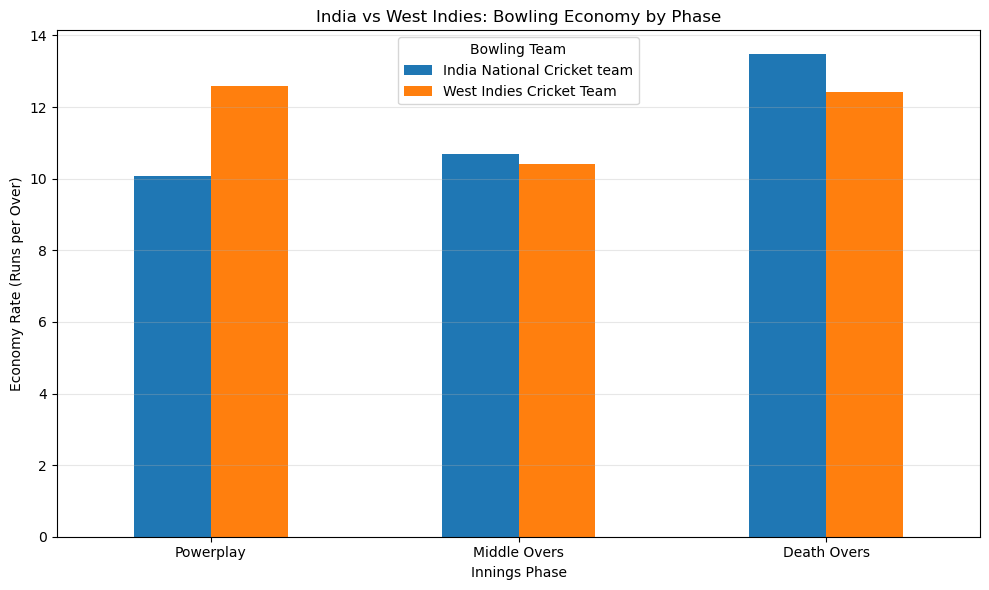

In [11]:
team_economy_pivot = team_phase_summary.pivot(
    index="Phase",
    columns="Bowling Team",
    values="Economy"
).reindex(["Powerplay", "Middle Overs", "Death Overs"])

ax = team_economy_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_xlabel("Innings Phase")
ax.set_ylabel("Economy Rate (Runs per Over)")
ax.set_title("India vs West Indies: Bowling Economy by Phase")
ax.legend(title="Bowling Team")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Keep bowlers with at least 12 legal balls in a phase
qualified_phase_bowlers = phase_bowling[
    phase_bowling["Legal_Balls"] >= 12
].copy()

# Rank bowlers within each phase
qualified_phase_bowlers["Economy_Rank"] = (
    qualified_phase_bowlers
    .groupby("Phase")["Economy"]
    .rank(method="min", ascending=True)
    .astype(int)
)

# Sort by phase, economy and wicket events
phase_order = {
    "Powerplay": 1,
    "Middle Overs": 2,
    "Death Overs": 3
}

qualified_phase_bowlers["Phase_Order"] = (
    qualified_phase_bowlers["Phase"].map(phase_order)
)

qualified_phase_bowlers = (
    qualified_phase_bowlers.sort_values(
        ["Phase_Order", "Economy", "Wicket_Events"],
        ascending=[True, True, False]
    )
    .drop(columns="Phase_Order")
    .reset_index(drop=True)
)

display(
    qualified_phase_bowlers[
        [
            "Phase",
            "Economy_Rank",
            "Bowler",
            "Bowling Team",
            "Overs",
            "Runs_Conceded",
            "Wicket_Events",
            "Economy"
        ]
    ]
)

,Phase,Economy_Rank,Bowler,Bowling Team,Overs,Runs_Conceded,Wicket_Events,Economy
0,Powerplay,1,Axar Patel,India National Cricket team,4.0,32,3,8.00
1,Powerplay,2,Mayank Yadav,India National Cricket team,9.0,90,3,10.00
2,Powerplay,2,Prince Yadav,India National Cricket team,2.0,20,0,10.00
3,Powerplay,4,Arshdeep Singh,India National Cricket team,9.0,100,2,11.11
4,Powerplay,5,Akeal Hosein,West Indies Cricket Team,5.0,56,1,11.20
5,Powerplay,6,Roston Chase,West Indies Cricket Team,7.0,83,2,11.86
6,Powerplay,7,Keemo Paul,West Indies Cricket Team,2.0,24,2,12.00
7,Powerplay,7,Romario Shepherd,West Indies Cricket Team,3.0,36,0,12.00
8,Powerplay,9,Shamar Joseph,West Indies Cricket Team,4.0,57,1,14.25
9,Powerplay,10,Shamar Springer,West Indies Cricket Team,2.0,31,0,15.50


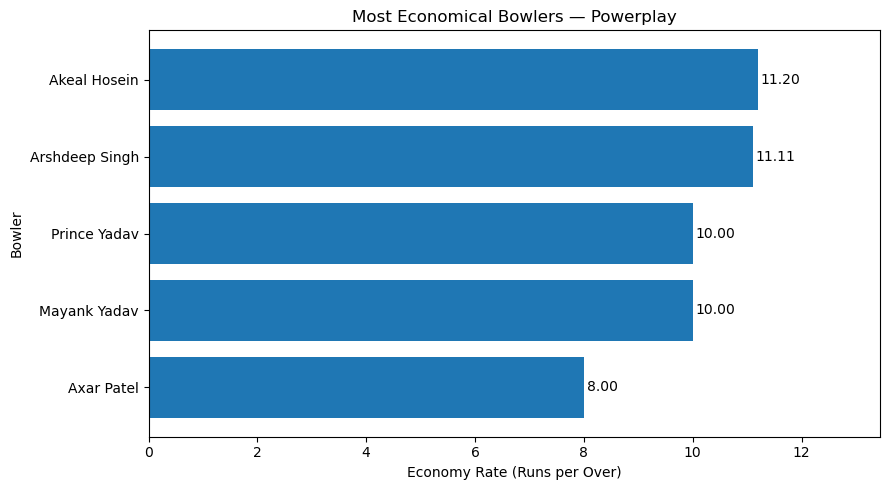

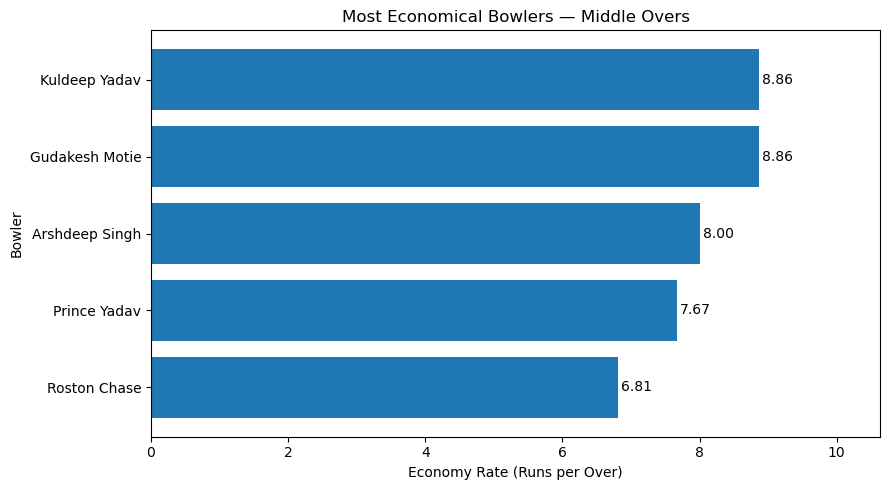

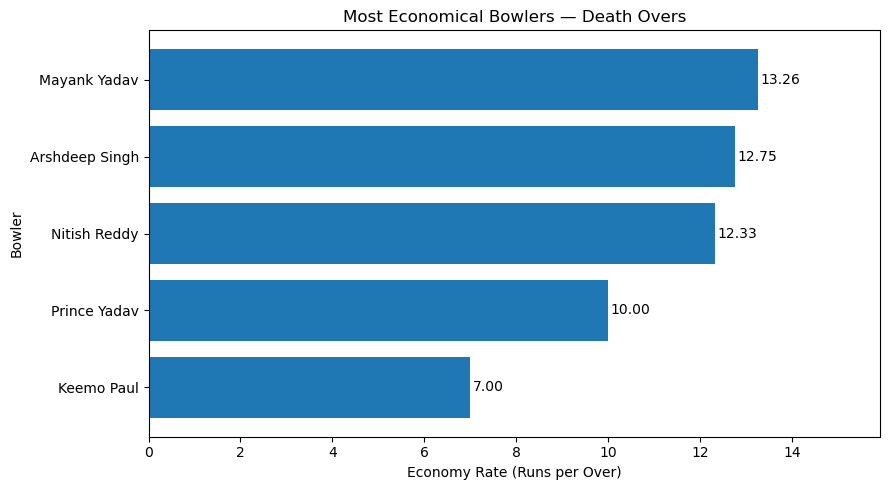

In [13]:
import matplotlib.pyplot as plt

phase_order = ["Powerplay", "Middle Overs", "Death Overs"]

for phase in phase_order:
    phase_top5 = (
        qualified_phase_bowlers[
            qualified_phase_bowlers["Phase"] == phase
        ]
        .sort_values("Economy")
        .head(5)
        .sort_values("Economy", ascending=True)
    )

    if phase_top5.empty:
        print(f"No qualified bowlers for {phase}")
        continue

    plt.figure(figsize=(9, 5))

    bars = plt.barh(
        phase_top5["Bowler"],
        phase_top5["Economy"]
    )

    for bar in bars:
        width = bar.get_width()
        plt.text(
            width + 0.05,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.2f}",
            va="center"
        )

    plt.xlabel("Economy Rate (Runs per Over)")
    plt.ylabel("Bowler")
    plt.title(f"Most Economical Bowlers — {phase}")
    plt.xlim(0, phase_top5["Economy"].max() * 1.2)
    plt.tight_layout()
    plt.show()

In [14]:
# Create output folders
PROCESSED_DIR = PROJECT_DIR / "Data" / "Processed"
VISUALS_DIR = PROJECT_DIR / "Visualizations"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

# Save analysis tables
phase_bowling.to_csv(
    PROCESSED_DIR / "phase_wise_bowling.csv",
    index=False
)

phase_summary.to_csv(
    PROCESSED_DIR / "phase_bowling_summary.csv",
    index=False
)

team_phase_summary.to_csv(
    PROCESSED_DIR / "team_phase_bowling_summary.csv",
    index=False
)

qualified_phase_bowlers.to_csv(
    PROCESSED_DIR / "qualified_phase_bowlers.csv",
    index=False
)

print("Phase-wise bowling tables saved successfully.")

Phase-wise bowling tables saved successfully.


In [15]:
plt.savefig(
    VISUALS_DIR / "overall_bowling_economy_by_phase.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [16]:
plt.savefig(
    VISUALS_DIR / "team_bowling_economy_by_phase.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [17]:
filename = phase.lower().replace(" ", "_")

plt.savefig(
    VISUALS_DIR / f"top_economical_bowlers_{filename}.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [18]:
print("PHASE-WISE CSV FILES")
for file in sorted(PROCESSED_DIR.glob("*phase*.csv")):
    print(file.name)

print("\nPHASE-WISE CHARTS")
for file in sorted(VISUALS_DIR.glob("*phase*.png")):
    print(file.name)

print("\nTOP-BOWLER CHARTS")
for file in sorted(VISUALS_DIR.glob("top_economical_bowlers_*.png")):
    print(file.name)

PHASE-WISE CSV FILES
phase_bowling_summary.csv
phase_wise_bowling.csv
qualified_phase_bowlers.csv
team_phase_bowling_summary.csv

PHASE-WISE CHARTS
overall_bowling_economy_by_phase.png
team_bowling_economy_by_phase.png

TOP-BOWLER CHARTS
top_economical_bowlers_death_overs.png


In [19]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\India_Vs_West_Indies_T20i_Challenge"
)

PROCESSED_DIR = PROJECT_DIR / "Data" / "Processed"

for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name)

bowling_performance_summary.csv
final_batting_leaderboard.csv
final_bowling_leaderboard.csv
match_bowling_performance.csv
overall_bowling_performance.csv
phase_bowling_summary.csv
phase_wise_bowling.csv
qualified_bowling_economy.csv
qualified_phase_bowlers.csv
team_phase_bowling_summary.csv


In [20]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\India_Vs_West_Indies_T20i_Challenge"
)

for folder in [
    PROJECT_DIR / "Data" / "Clean",
    PROJECT_DIR / "Data" / "Processed",
]:
    print(f"\n📁 {folder.name}")
    if folder.exists():
        for file in sorted(folder.glob("*.csv")):
            print(f"  {file.name}")
    else:
        print("  Folder not found")


📁 Clean
  t20i_ball_by_ball_clean.csv

📁 Processed
  bowling_performance_summary.csv
  final_batting_leaderboard.csv
  final_bowling_leaderboard.csv
  match_bowling_performance.csv
  overall_bowling_performance.csv
  phase_bowling_summary.csv
  phase_wise_bowling.csv
  qualified_bowling_economy.csv
  qualified_phase_bowlers.csv
  team_phase_bowling_summary.csv
